# N5. 발현 프로그램과 다른 응용: 세포가 여러 프로그램을 함께 쓸 때

**목표**
- 유전자 × 세포 개수 행렬에서 "세포형 프로그램"과 여러 세포형이 함께 쓰는 "활동 프로그램"(예: 세포 분열)을 NMF 로 찾습니다.
- NMF 전에 왜 정규화(유전자 고르기, 분산 맞추기)를 하는지 숫자로 봅니다.
- 여러 번 돌려 안정한 성분만 남기는 consensus NMF(cNMF)의 생각을 직접 따라 합니다.
- CN signature, metagene 같은 다른 응용과, 토픽 모형과의 닮은 점을 짧게 봅니다.

**이 노트북이 답하는 질문**: 세포를 한 군집에만 넣는 클러스터링으로는 놓치는 "세포형 + 활동"을 NMF 는 어떻게 함께 잡나?

**이어지는 노트북**: N4 는 mutational signature 에 같은 생각을 썼습니다. 이 노트북의 데이터는 모두 **이 노트북이 만든 장난감 단일세포 데이터**입니다.

In [1]:
# 그림 도구 (펼치지 않아도 됩니다). 팔레트: Okabe-Ito. 성분(프로그램) 색은 N1–N5 공통 순서, 핵심 메시지는 자주색 하나.
import logging, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle
from scipy.optimize import linear_sum_assignment, nnls
from sklearn.decomposition import NMF, PCA
from sklearn.cluster import KMeans
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 10)

COL = dict(ink="#222222", muted="#6B7280", grid="#E5E7EB", none="#D1D5DB", shade="#F3F4F6", highlight="#CC79A7", true="#374151",
           data="#6B7280", facU="#1F2937", facG="#78716C", metric="#111827", metric2="#9CA3AF")
COMP = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#56B4E9", "#F0E442", "#6B7280", "#9CA3AF", "#374151", "#BBBBBB"]   # N1–N5 공통(_palette.py): 성분 1, 2, 3 ...
TYPE_C = {"A": COMP[0], "B": COMP[1], "C": COMP[2]}                                                 # 세포형 = 그 세포형 프로그램 색
ACT_C = COMP[3]                                                                                       # 활동(분열) 프로그램

def apply_theme():
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
    plt.rcParams.update({
        "font.family": ["Arial", "DejaVu Sans"], "font.size": 10.5, "mathtext.fontset": "dejavusans",
        "axes.titlesize": 11.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
        "axes.titlepad": 10, "axes.labelsize": 10.5, "axes.labelcolor": COL["ink"],
        "axes.edgecolor": "#9CA3AF", "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": False, "grid.color": COL["grid"], "grid.linewidth": 0.8,
        "xtick.color": COL["muted"], "ytick.color": COL["muted"],
        "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
        "legend.frameon": False, "legend.fontsize": 9.5,
        "figure.dpi": 110, "savefig.bbox": "tight", "figure.facecolor": "white"})

def panel(ax, letter, title):
    ax.set_title(f"{letter}   {title}")

def note(ax, x, y, text, **kw):
    kw.setdefault("fontsize", 9); kw.setdefault("color", COL["muted"])
    return ax.text(x, y, text, **kw)

def callout(ax, x, y, text, **kw):
    kw.setdefault("fontsize", 10); kw.setdefault("color", COL["highlight"]); kw.setdefault("fontweight", "semibold")
    kw.setdefault("bbox", dict(facecolor="white", edgecolor="none", pad=1.5, alpha=0.9))
    return ax.text(x, y, text, **kw)

def ygrid(ax):
    ax.yaxis.grid(True); ax.set_axisbelow(True)

def formula_strip(ax, parts, y=0.5, fontsize=17, gap=0.03):
    """수식 조각 그림. parts = [(mathtext, 색 또는 None, 이름표 또는 None), ...]"""
    ax.set_axis_off(); fig = ax.figure
    r = fig.canvas.get_renderer(); inv = ax.transAxes.inverted(); x = 0.0; items = []
    for tex, color, label in parts:
        t = ax.text(0, y, tex, fontsize=fontsize, va="center", ha="left", color=color or COL["ink"], transform=ax.transAxes)
        bb = t.get_window_extent(renderer=r).transformed(inv)
        lw = 0.0
        if label:
            lt = ax.text(0, 0, label, fontsize=9.5, fontweight="semibold", transform=ax.transAxes)
            lw = lt.get_window_extent(renderer=r).transformed(inv).width; lt.remove()
        slot = max(bb.width, lw)
        items.append((t, bb, color, label, x + (slot - bb.width) / 2)); x += slot + gap
    shift = (1 - (x - gap)) / 2
    for t, bb, color, label, x0 in items:
        t.set_x(x0 + shift)
        if color:
            ax.add_patch(FancyBboxPatch((x0 + shift - 0.006, bb.y0 - 0.04), bb.width + 0.012, bb.height + 0.08,
                                        boxstyle="round,pad=0,rounding_size=0.02", transform=ax.transAxes,
                                        facecolor=color, alpha=0.13, edgecolor="none", zorder=0))
        if label:
            ax.text(x0 + shift + bb.width / 2, bb.y0 - 0.12, label, ha="center", va="top", fontsize=9.5,
                    color=color or COL["muted"], fontweight="semibold", transform=ax.transAxes)

def show_formula(parts, title=None, height=1.5, width=11):
    fig, ax = plt.subplots(figsize=(width, height))
    formula_strip(ax, parts)
    if title:
        ax.text(0.5, 1.05, title, ha="center", va="bottom", fontsize=11.5, fontweight="semibold", transform=ax.transAxes)
    plt.show()

def concept_map(nodes, edges, title="Concept map", size=(11, 3.2)):
    fig, ax = plt.subplots(figsize=size)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_axis_off()
    boxes = {}
    for k, (x, y, text, c) in nodes.items():
        boxes[k] = ax.text(x, y, text, ha="center", va="center", fontsize=10, color=COL["ink"], zorder=3,
                           bbox=dict(boxstyle="round,pad=0.45", facecolor=c, alpha=0.22 if c != "white" else 1,
                                     edgecolor=c if c != "white" else COL["muted"], linewidth=1.0))
    fig.canvas.draw(); r = fig.canvas.get_renderer(); inv = ax.transAxes.inverted(); ext = {}
    for k, t in boxes.items():
        bb = t.get_bbox_patch().get_window_extent(r).transformed(inv); ext[k] = (bb.x0, bb.y0, bb.x1, bb.y1)

    def edge_point(k, dx, dy):
        x0, y0, x1, y1 = ext[k]; cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
        hw, hh = (x1 - x0) / 2 + 0.008, (y1 - y0) / 2 + 0.02
        s = min(hw / abs(dx) if dx else 1e9, hh / abs(dy) if dy else 1e9)
        return cx + dx * s, cy + dy * s

    for a, b, lab in edges:
        (ax0, ay0, ax1, ay1), (bx0, by0, bx1, by1) = ext[a], ext[b]
        dx, dy = (bx0 + bx1) / 2 - (ax0 + ax1) / 2, (by0 + by1) / 2 - (ay0 + ay1) / 2
        p0 = edge_point(a, dx, dy); p1 = edge_point(b, -dx, -dy)
        ax.annotate("", xy=p1, xytext=p0, xycoords="axes fraction", textcoords="axes fraction",
                    arrowprops=dict(arrowstyle="-|>", color=COL["muted"], lw=1.0, mutation_scale=12, shrinkA=0, shrinkB=0), zorder=2)
        if lab:
            note(ax, (p0[0] + p1[0]) / 2, (p0[1] + p1[1]) / 2 + 0.05, lab, ha="center", fontsize=8.5, transform=ax.transAxes)
    ax.set_title(title)
    plt.show()

def corr_cols(A, B):
    """A: g × a, B: g × b 의 열끼리 Pearson 상관 → a × b"""
    A = (A - A.mean(0)) / A.std(0); B = (B - B.mean(0)) / B.std(0)
    return A.T @ B / A.shape[0]

def match(T, E):
    """T, E: g × k. 상관 합이 가장 큰 1:1 짝. 반환: E 의 열 순서, 짝지은 상관"""
    C = corr_cols(T, E); r, c = linear_sum_assignment(C, maximize=True)
    return c, C[r, c]

apply_theme()

## 개념 지도

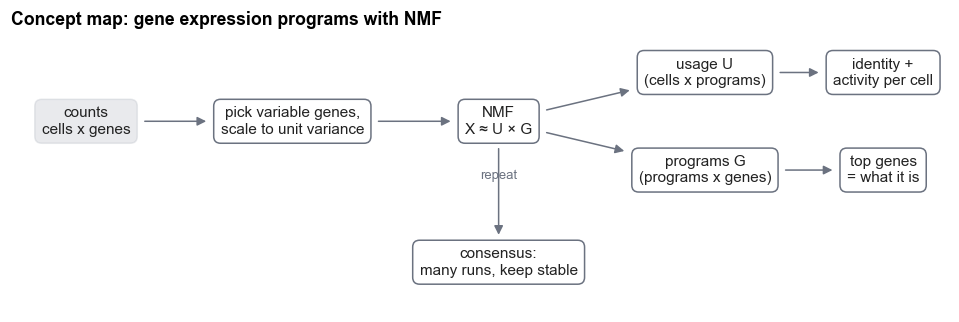

In [2]:
concept_map({
    "cnt": (0.08, 0.70, "counts\ncells x genes", "#9CA3AF"),
    "norm": (0.30, 0.70, "pick variable genes,\nscale to unit variance", "white"),
    "nmf": (0.52, 0.70, "NMF\nX ≈ U × G", "white"),
    "use": (0.74, 0.88, "usage U\n(cells x programs)", "white"),
    "gep": (0.74, 0.52, "programs G\n(programs x genes)", "white"),
    "cons": (0.52, 0.18, "consensus:\nmany runs, keep stable", "white"),
    "read": (0.93, 0.52, "top genes\n= what it is", "white"),
    "cl": (0.93, 0.88, "identity +\nactivity per cell", "white"),
}, [("cnt", "norm", ""), ("norm", "nmf", ""), ("nmf", "use", ""), ("nmf", "gep", ""), ("nmf", "cons", "repeat"),
    ("gep", "read", ""), ("use", "cl", "")], title="Concept map: gene expression programs with NMF")

**그림에서 볼 것**: 개수 행렬을 먼저 다듬고(유전자 고르기, 분산 맞추기), NMF 로 "세포마다 프로그램을 얼마나 쓰나(usage)"와 "프로그램마다 어떤 유전자를 켜나(program)"로 나눕니다.
한 번만 돌리면 결과가 흔들리므로 여러 번 돌려 안정한 성분만 남깁니다(consensus).

## 먼저 알아 둘 것

### 1. 세포형 프로그램과 활동 프로그램

**한 줄 정의**: 유전자 발현 프로그램(GEP)은 함께 켜지고 꺼지는 유전자 묶음입니다. **세포형(identity) 프로그램**은 한 세포형에서만, **활동(activity) 프로그램**은 세포 분열처럼 여러 세포형에서 켜질 수 있습니다 [1].

**왜 필요한가**: 클러스터링은 세포 하나를 군집 하나에만 넣습니다. 분열이 강한 A 형 세포를 따로 한 군집으로 모을 수는 있어도(6절에서 실제로 그렇게 됩니다), 그 군집 번호는 (1) A 형의 분열과 B 형의 분열이 **같은 프로그램**이라는 것과 (2) 세포마다 **얼마나** 분열 프로그램을 쓰는지(φ)를 말해 주지 않습니다. Kotliar 등은 "모든 세포를 한 군집의 공통 프로그램으로 줄이는 hard clustering 과 달리, 행렬 분해는 세포가 여러 프로그램을 함께 쓰게 한다"고 적었습니다 [1].

**숫자로 따라가기**: Kotliar 등의 시뮬레이션은 세포 i 의 기댓값을 $\lambda_i = L_i\,(\phi_i Z_{act} + (1-\phi_i) Z_{type(i)})$ 로 둡니다. $L_i$ 는 그 세포의 총 개수(library size), $\phi_i$ 는 활동 프로그램을 쓰는 몫(쓰지 않는 세포는 0, 쓰는 세포는 0.1~0.7 사이 균등)입니다 [1]. Kotliar 등의 시뮬레이션은 Splatter(단일세포 데이터 흉내 도구)를 바탕으로 했고, 이 λ 는 Splatter 가 잡음을 더하기 전의 평균입니다 [1]. 이 노트북은 같은 식으로 평균을 만들고 **포아송 잡음만** 더했습니다(Splatter 의 추가 잡음은 뺌). 대신 RP 유전자의 흔들림을 따로 넣었습니다(2절).

| 세포 | 세포형 | $\phi$ | 세포형 프로그램 몫 | 활동 프로그램 몫 |
|---|---|---|---|---|
| 1 | A | 0 | 100% | 0% |
| 2 | A | 0.4 | 60% | 40% |
| 3 | C | 0 | 100% | 0% |

### 2. 데이터 모양: 세포 × 유전자, 그리고 방향

**한 줄 정의**: 단일세포 개수 행렬은 보통 **세포 × 유전자**(행 = 세포)로 둡니다. scikit-learn 의 X(표본 × 특징)와 방향이 같아서, N4 의 catalog(96칸 × 표본)와 달리 전치 없이 넣으면 됩니다 [2].

아래에서 세포 900개 × 유전자 400개 장난감 데이터를 만듭니다.
- 세포형 A·B·C 마다 표지 유전자 40개, 분열(CYC) 프로그램 유전자 30개. 분열 프로그램은 세포형 표지보다 약하게 만들었습니다.
- RP 유전자 15개는 아주 많이 발현되고, 세포형과 상관없이 세포마다 따로 흔들리게 했습니다. 생물학 프로그램이 아닌 **기술적 변동**을 흉내 낸 이 노트북의 가정입니다.
- 나머지 HK 유전자는 모든 세포에서 비슷하게 발현됩니다.

In [3]:
def make_programs(seed=4):
    rng = np.random.default_rng(seed)
    genes = [f"A{i:02d}" for i in range(1, 41)] + [f"B{i:02d}" for i in range(1, 41)] + [f"C{i:02d}" for i in range(1, 41)] \
            + [f"CYC{i:02d}" for i in range(1, 31)] + [f"RP{i:02d}" for i in range(1, 16)] + [f"HK{i:03d}" for i in range(1, 236)]
    g = len(genes); base = rng.gamma(0.8, 1.0, g)                      # 유전자마다 기본 발현 수준이 다르다
    rp = [i for i, n in enumerate(genes) if n.startswith("RP")]; base[rp] *= 60   # 아주 많이 발현되는 유전자 15개
    Z = {}
    for t in "ABC":
        z = base.copy(); idx = [i for i, n in enumerate(genes) if n.startswith(t) and n[1:].isdigit()]
        z[idx] *= rng.uniform(6, 14, len(idx)); Z[t] = z / z.sum()
    z = base.copy(); idx = [i for i, n in enumerate(genes) if n.startswith("CYC")]
    z[idx] *= rng.uniform(3, 6, len(idx)); Z["CYC"] = z / z.sum()                 # 세포형 표지보다 약한 활동 프로그램
    return genes, pd.DataFrame(Z, index=genes)

def simulate_cells(Z, n=(400, 300, 200), act_frac=(0.4, 0.3, 0.0), seed=5):
    rng = np.random.default_rng(seed)
    types = np.repeat(list("ABC"), n); N = len(types)
    phi = np.zeros(N)
    for t, f in zip("ABC", act_frac):
        idx = np.flatnonzero(types == t); on = rng.random(len(idx)) < f
        phi[idx[on]] = rng.uniform(0.1, 0.7, on.sum())                 # Kotliar 시뮬레이션과 같은 범위 [1]
    L = np.round(np.exp(rng.normal(np.log(3000), 0.45, N)))           # library size
    lam = L[:, None] * (phi[:, None] * Z["CYC"].values + (1 - phi[:, None]) * Z[list(types)].values.T)
    rp = [i for i, g in enumerate(Z.index) if g.startswith("RP")]
    lam[:, rp] *= np.exp(rng.normal(0, 0.5, N))[:, None]            # 이 장난감의 가정: RP 유전자만 세포마다 따로 흔들림(기술적 변동)
    counts = rng.poisson(lam)
    cells = [f"cell{i:04d}" for i in range(N)]
    return pd.DataFrame(counts, index=cells, columns=Z.index), pd.DataFrame({"type": types, "phi": phi, "lib": L}, index=cells)

genes, Z_true = make_programs()
counts, meta = simulate_cells(Z_true)
print("개수 행렬 counts:", counts.shape, "(세포 × 유전자)")
print(f"0 인 칸의 비율: {(counts.values == 0).mean():.1%} | 세포당 총 개수 중앙값 {int(counts.sum(1).median())}")
print("세포형별 세포 수:", meta.type.value_counts().to_dict(), "| 분열 프로그램을 쓰는 세포:", int((meta.phi > 0).sum()))
counts.iloc[:5, list(range(3)) + [41, 81, 121, 150, 165]]

개수 행렬 counts: (900, 400) (세포 × 유전자)
0 인 칸의 비율: 30.0% | 세포당 총 개수 중앙값 3204
세포형별 세포 수: {'A': 400, 'B': 300, 'C': 200} | 분열 프로그램을 쓰는 세포: 265


,A01,A02,A03,B02,C02,CYC02,RP01,HK001
cell0000,74,17,30,0,1,2,133,7
cell0001,26,6,15,0,1,1,148,4
cell0002,75,11,41,0,2,2,394,6
cell0003,54,13,30,0,7,1,229,5
cell0004,50,9,32,0,4,7,359,5


In [4]:
meta.head()

,type,phi,lib
cell0000,A,0.000000,2840.0
cell0001,A,0.000000,1509.0
cell0002,A,0.000000,3270.0
cell0003,A,0.174858,2448.0
cell0004,A,0.312109,2987.0


**표에서 볼 것**
- 행은 세포, 열은 유전자입니다. A01 은 A 형 표지, B02 는 B 형, C02 는 C 형, CYC02 는 분열, RP01 은 많이 발현되며 따로 흔들리는 유전자, HK 는 어디서나 비슷한 유전자입니다.
- 0 이 많습니다(단일세포 데이터의 특징). 총 개수(lib)는 세포마다 다릅니다.
- `meta` 의 `phi` 가 0 보다 큰 세포가 분열 프로그램을 함께 쓰는 세포입니다. 실제 데이터에는 이 정답 열이 없습니다.

## 3. NMF 전에 다듬기: 왜 유전자를 고르고 분산을 맞추나

**한 줄 정의**: cNMF 논문은 (1) UMI 가 너무 적은 세포와 거의 안 잡히는 유전자를 빼고, (2) 세포 사이에 많이 흔들리는(over-dispersed) 유전자를 골라, (3) 고른 유전자마다 **표준편차로 나눠 분산을 1 로** 맞춘 뒤 NMF 를 돌렸습니다 [1].

처음 나오는 이름 풀이:
- **UMI**(unique molecular identifier): mRNA 분자마다 붙이는 짧은 무작위 바코드. PCR 로 불어난 읽기를 한 분자로 세게 해 주어서, "UMI 개수 ≈ 그 세포에서 잡힌 mRNA 분자 수"입니다.
- **v-score**: 흔들림이 큰 유전자를 고르는 점수. cNMF 논문은 Klein 등(2015)의 것을 썼습니다 [1][6]. Klein 등 본문의 생각은 "개수 잡음(포아송)만으로 예상되는 것보다 얼마나 더 흔들리나"(above-Poisson noise, CV² − 1/평균)입니다 [6]. v-score 의 정확한 식은 이 노트북이 확인하지 못했습니다.

**왜 필요한가**: NMF 의 제곱 오차는 숫자가 큰 유전자에 끌려갑니다. 많이 발현되는 유전자 몇 개가 오차를 거의 다 차지하면, 적게 발현되지만 정보가 많은 유전자는 무시됩니다. Kotliar 등은 분산 맞추기가 "발현 크기가 다른 유전자들이 비슷한 양의 정보를 내게 한다"고 적었습니다 [1]. 평균을 빼지 않고 나누기만 하므로 값은 여전히 0 이상이라 NMF 에 넣을 수 있습니다.

**순서가 중요합니다**: 유전자를 먼저 고르고 그다음 분산을 맞춥니다. Kotliar 등은 "정규화 전에 흔들리는 유전자를 골라야 한다. 그 뒤에는 분산이 작은 유전자의 잡음이 생물학적 변동과 같은 크기가 되기 때문"이라고 적었습니다("It is essential to select a subset of over-dispersed genes prior to normalization because afterwards, variation in lower-variance genes due to noise will be on the same scale as biologically meaningful variation") [1]. 모든 유전자의 분산을 1 로 맞춘 뒤에는 잡음뿐인 유전자와 정보가 있는 유전자를 분산으로 가를 수 없습니다.

**세부(실제 cNMF 와 같은 점·다른 점)**
- cNMF 논문은 UMI 1000 개 미만 세포를 빼고, 500 개 세포 중 1 개에서도 안 잡히는 유전자를 뺐습니다. 그리고 v-score 로 가장 흔들리는 유전자 2000 개를 골랐습니다 [1].
- 이 노트북은 유전자가 400 개뿐이라 "분산/평균"이 큰 200 개를 고릅니다(공부용으로 줄인 것).

In [5]:
keep_cells = counts.sum(1) >= 1000                                   # UMI 1000 개 미만 세포 빼기 [1]
keep_genes = (counts > 0).mean(0) >= 1 / 500                         # 500 세포 중 1 개 이상에서 잡힌 유전자 [1]
C = counts.loc[keep_cells, keep_genes]
disp = C.var(0) / C.mean(0)                                          # 분산/평균 (이 노트북의 간단한 흔들림 지표)
hv = disp.sort_values(ascending=False).index[:200]
X = C[hv] / C[hv].std(0)                                             # 유전자마다 표준편차로 나누기(평균은 빼지 않음) [1]
print("세포", keep_cells.sum(), "/", len(counts), "| 유전자", keep_genes.sum(), "→ 흔들리는 유전자", len(hv))
print("고른 200 개 중 표지·분열:", int(sum(g[0] in "ABC" or g.startswith("CYC") for g in hv)), "개 | RP:", int(sum(g.startswith("RP") for g in hv)),
      "개 | HK:", int(sum(g.startswith("HK") for g in hv)), "개")
print("X:", X.shape, "| 최솟값", float(X.values.min()), "(음수 없음)")
assert X.values.min() >= 0 and np.allclose(X.std(0), 1)

세포 887 / 900 | 유전자 399 → 흔들리는 유전자 200
고른 200 개 중 표지·분열: 133 개 | RP: 14 개 | HK: 53 개
X: (887, 200) | 최솟값 0.0 (음수 없음)


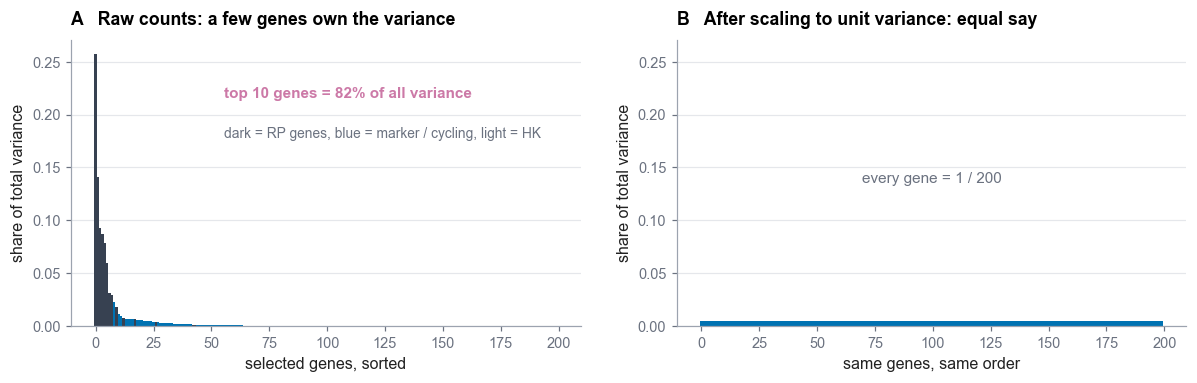

In [6]:
def draw_scaling(C, X):
    raw_var = C[X.columns].var(0); share_raw = raw_var / raw_var.sum()
    order = np.argsort(-share_raw.values)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    gcol = [COL["true"] if X.columns[i].startswith("RP") else (COL["none"] if X.columns[i].startswith("HK") else COMP[0]) for i in order]
    ax[0].bar(np.arange(len(order)), share_raw.values[order], color=gcol, width=1.0, lw=0)
    note(ax[0], 0.30, 0.66, "dark = RP genes, blue = marker / cycling, light = HK", transform=ax[0].transAxes)
    ax[0].set_xlabel("selected genes, sorted"); ax[0].set_ylabel("share of total variance")
    panel(ax[0], "A", "Raw counts: a few genes own the variance"); ygrid(ax[0])
    top10 = share_raw.values[order][:10].sum()
    callout(ax[0], 0.30, 0.80, f"top 10 genes = {top10:.0%} of all variance", transform=ax[0].transAxes)
    ax[1].bar(np.arange(len(order)), np.full(len(order), 1 / len(order)), color=COMP[0], width=1.0, lw=0)
    ax[1].set_ylim(0, share_raw.max() * 1.05); ax[1].set_xlabel("same genes, same order"); ax[1].set_ylabel("share of total variance")
    panel(ax[1], "B", "After scaling to unit variance: equal say"); ygrid(ax[1])
    note(ax[1], 0.5, 0.5, "every gene = 1 / 200", transform=ax[1].transAxes, ha="center", fontsize=10)
    plt.tight_layout(); plt.show()
    return top10

top10 = draw_scaling(C, X)

**그림에서 볼 것**
- A: 원래 개수에서는 분산(흔들림의 크기)이 몇몇 유전자에 몰려 있습니다. 진한 막대(RP 유전자)가 맨 앞을 차지합니다. 제곱 오차로 맞추면 NMF 가 주로 이 유전자들을 맞추려 듭니다.
- B: 표준편차로 나누면 모든 유전자의 분산이 1 이 되어 같은 몫을 냅니다.

실제로 결과가 달라지는지는 4절 끝에서 확인합니다.

## 4. NMF 로 나누기: X ≈ U × G

**한 줄 정의**: 다듬은 행렬 X(세포 × 유전자)를 **usage U(세포 × k)** 와 **프로그램 G(k × 유전자)** 의 곱으로 나눕니다. U 의 한 행은 "그 세포가 각 프로그램을 얼마나 쓰나", G 의 한 행은 "그 프로그램이 각 유전자를 얼마나 켜나"입니다 [1].

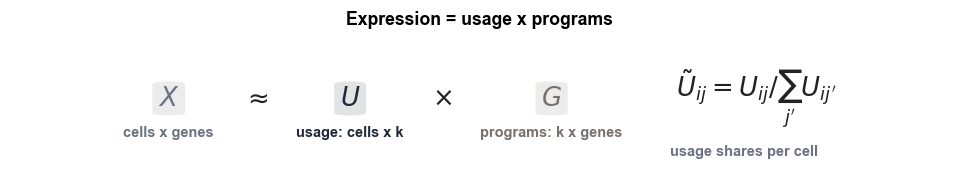

In [7]:
show_formula([
    (r"$X$", COL["data"], "cells x genes"),
    (r"$\approx$", None, None),
    (r"$U$", COL["facU"], "usage: cells x k"),
    (r"$\times$", None, None),
    (r"$G$", COL["facG"], "programs: k x genes"),
    (r"$\quad \tilde U_{ij} = U_{ij} / \sum_{j'} U_{ij'}$", None, "usage shares per cell"),
], title="Expression = usage x programs")

| 기호 | 소리 내어 읽기 | 뜻 |
|---|---|---|
| $U_{ij}$ | "유 아이 제이" | 세포 i 가 프로그램 j 를 쓰는 양 |
| $G_{jg}$ | "지 제이 지" | 프로그램 j 에서 유전자 g 의 무게 |
| $\sum_{j'} U_{ij'}$ | "세포 i 의 usage 를 프로그램마다 더하기" | 세포 i 의 usage 합. j′ 는 1 부터 k 까지 도는 이름일 뿐입니다 |
| $\tilde U_{ij}$ | "유 틸데 아이 제이" | 세포 i 의 usage 를 합이 1 이 되게 나눈 것(몫). cNMF 도 usage 를 세포마다 합 1 로 맞춥니다 [1] |

k 는 프로그램 개수, j 는 그중 하나를 가리키는 번호입니다.

**숫자 넣기**: 프로그램이 4개(A, B, C, 분열)이고 세포 i 의 usage 가 U_i = (6, 0, 0, 4) 이면 합은 10, 몫은 (0.6, 0, 0, 0.4) 입니다. "A 형 프로그램 60%, 분열 프로그램 40%"로 읽습니다. 1절 표의 세포 2(A 형, φ = 0.4)와 같은 모양입니다.

scikit-learn 에서는 `W = model.fit_transform(X)` 가 U, `model.components_` 가 G 입니다 [2]. 이 데이터는 이미 세포 × 유전자라 전치하지 않습니다.

**크기 모호함 정리**: U 의 열 하나를 c 배 하고 G 의 그 행을 1/c 배 해도 곱은 같습니다(N2). 그대로 두면 usage 몫이 뜻을 잃으므로, 아래 `fit_nmf()` 는 G 의 각 행을 합 1 로 맞추고 그만큼 U 를 키웁니다. 그러면 usage 몫이 "그 세포의 (척도 맞춘) 발현 가운데 그 프로그램이 설명하는 몫"이 됩니다.

In [8]:
def fit_nmf(X, k, seed=0, max_iter=800, init="nndsvda"):
    """init="nndsvda" 는 SVD 로 시작점을 정해 매번 같은 답, init="random" 은 시드마다 다른 시작점"""
    model = NMF(n_components=k, init=init, solver="cd", beta_loss="frobenius", max_iter=max_iter, tol=1e-5, random_state=seed)
    U = model.fit_transform(X); G = model.components_
    s = G.sum(axis=1)                                               # 크기 모호함 정리: 프로그램 행을 합 1 로, 그만큼 U 를 키운다
    return U * s, G / s[:, None], model.reconstruction_err_

U, G, err = fit_nmf(X.values, 4)
print("U:", U.shape, "(세포 × 프로그램) | G:", G.shape, "(프로그램 × 유전자)")
truth = Z_true.loc[hv]                                               # 정답 프로그램(고른 유전자만)
truth_scaled = truth.values / C[hv].std(0).values[:, None]           # 같은 척도로
order, r = match(truth_scaled, G.T)
U, G = U[:, order], G[order]
print("정답 프로그램과의 상관(짝 맞춘 뒤):", dict(zip(truth.columns, r.round(3))))
assert r.min() > 0.9

U: (887, 4) (세포 × 프로그램) | G: (4, 200) (프로그램 × 유전자)
정답 프로그램과의 상관(짝 맞춘 뒤): {'A': 0.964, 'B': 0.968, 'C': 0.977, 'CYC': 0.977}


### 분산을 맞추지 않고 돌리면?

같은 k = 4 로, 표준편차로 나누지 않은 개수 `C[hv]` 를 넣어 봅니다. 비교는 Kotliar 등처럼 유전자마다 표준편차로 나눈 척도에서 상관으로 합니다 [1].

In [9]:
sd_hv = C[hv].std(0).values
_, Graw, _ = fit_nmf(C[hv].values, 4)
o_raw, r_raw = match(truth_scaled, (Graw / sd_hv).T)
lost = [j for j in range(4) if j not in o_raw[r_raw > 0.9]]
print("분산 맞춤  : 정답과 상관", dict(zip(truth.columns, r.round(3))))
print("맞추지 않음: 정답과 상관", dict(zip(truth.columns, r_raw.round(3))))
for j in lost:
    top = pd.Series(Graw[j], index=hv).sort_values(ascending=False)[:6]
    print(f"  정답과 짝을 못 찾은 성분 {j + 1} 의 대표 유전자:", list(top.index))
assert r_raw.min() < 0.6 < r.min()

분산 맞춤  : 정답과 상관 {'A': 0.964, 'B': 0.968, 'C': 0.977, 'CYC': 0.977}
맞추지 않음: 정답과 상관 {'A': 0.958, 'B': 0.963, 'C': 0.967, 'CYC': 0.285}
  정답과 짝을 못 찾은 성분 4 의 대표 유전자: ['RP11', 'RP01', 'RP03', 'RP12', 'RP13', 'RP06']


**표에서 볼 것**: 분산을 맞추지 않으면 정답 프로그램 하나(보통 약한 분열 프로그램)와 짝이 맞지 않고, 대신 한 성분의 대표 유전자가 RP 유전자로 채워집니다. 많이 발현되는 유전자의 흔들림이 오차를 크게 차지해 성분 하나를 통째로 가져간 것입니다(이 노트북의 시뮬레이션 결과). 분산을 맞추면 네 프로그램을 모두 찾습니다.

## 5. 결과 읽기: 프로그램의 대표 유전자와 세포별 usage

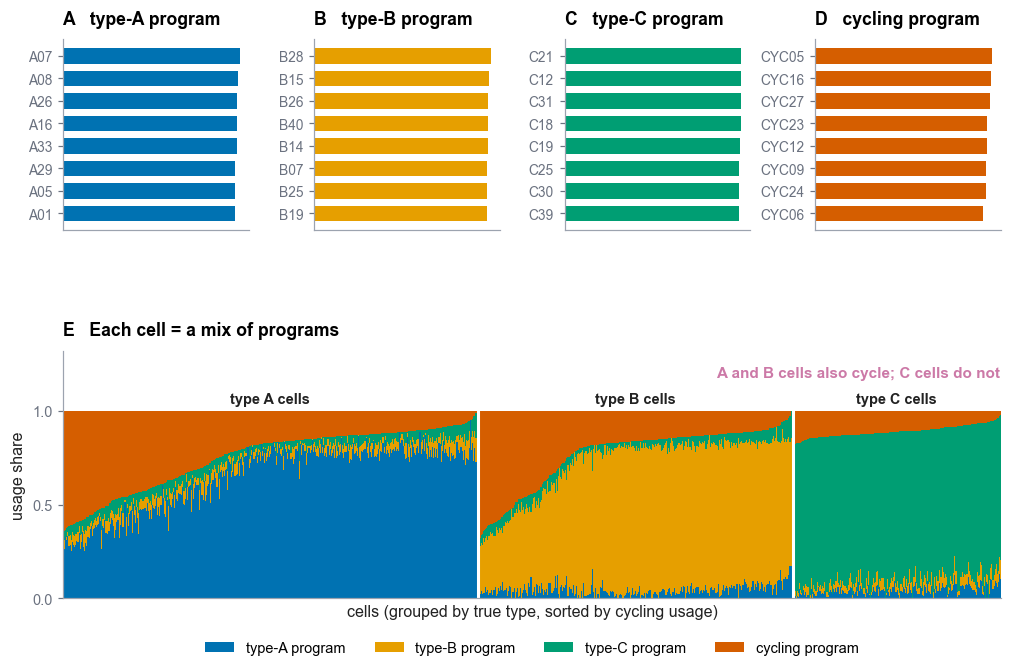

In [10]:
def draw_programs(G, U, genes, meta, names=("type-A program", "type-B program", "type-C program", "cycling program")):
    Gs = pd.DataFrame(G, columns=genes, index=names)
    fig = plt.figure(figsize=(11, 6.6)); gs = fig.add_gridspec(2, 4, height_ratios=[1, 1.3], hspace=0.55, wspace=0.35)
    for i, nm in enumerate(names):
        ax = fig.add_subplot(gs[0, i]); top = Gs.loc[nm].sort_values(ascending=False)[:8][::-1]
        ax.barh(range(8), top.values, color=COMP[i] if i < 3 else ACT_C, height=0.7)
        ax.set_yticks(range(8), top.index, fontsize=9); ax.set_xticks([])
        panel(ax, "ABCD"[i], nm)
    Us = U / U.sum(1, keepdims=True)
    idx = np.lexsort((-Us[:, 3], meta.type.values))
    ax = fig.add_subplot(gs[1, :])
    bottom = np.zeros(len(idx))
    for i, nm in enumerate(names):
        ax.bar(np.arange(len(idx)), Us[idx, i], bottom=bottom, width=1.0, lw=0, color=COMP[i] if i < 3 else ACT_C, label=nm)
        bottom += Us[idx, i]
    ty = meta.type.values[idx]
    for t in "ABC":
        pos = np.flatnonzero(ty == t)
        ax.text(pos.mean(), 1.04, f"type {t} cells", ha="center", fontsize=9.5, color=COL["ink"], fontweight="semibold")
        if t != "A":
            ax.axvline(pos.min() - 0.5, color="white", lw=2)
    ax.set_xlim(-0.5, len(idx) - 0.5); ax.set_ylim(0, 1.32); ax.set_yticks([0, 0.5, 1]); ax.set_xticks([]); ax.set_ylabel("usage share")
    ax.set_xlabel("cells (grouped by true type, sorted by cycling usage)")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4)
    panel(ax, "E", "Each cell = a mix of programs")
    callout(ax, len(idx) - 1, 1.20, "A and B cells also cycle; C cells do not", ha="right", va="center")
    plt.show()

draw_programs(G, U, list(hv), meta.loc[X.index])

**그림에서 볼 것**
- A–D: 각 프로그램에서 무게가 큰 유전자 8개입니다. 그림 A(type-A program)는 A 로 시작하는 표지 유전자, 그림 D(cycling program, 분열)는 CYC 유전자가 위에 옵니다. 패널 글자 A–D 와 세포형 A·B·C 는 서로 다른 것입니다. 실제 데이터에서는 이 목록을 보고 프로그램 이름을 붙입니다.
- E: 세포 하나가 막대 하나이고, 색 몫이 그 세포의 usage 몫입니다. A·B 형 세포 중 일부는 빨간 분열 프로그램 몫이 큽니다. C 형 세포(이 장난감에서는 분열하지 않게 만듦)의 분열 몫은 작습니다.
- 분열하지 않는 세포도 분열 몫이 0 은 아닙니다(바로 아래 출력의 중앙값). 모든 프로그램이 모든 세포에 공통인 바탕 발현(HK 유전자)을 조금씩 담고 있어서, 세포의 바탕 발현 일부가 분열 프로그램 몫으로도 나뉘기 때문입니다. 그래서 몫의 절댓값보다 세포 사이의 차이를 봅니다.

In [11]:
Us = U / U.sum(1, keepdims=True)
m = meta.loc[X.index]
rho = np.corrcoef(Us[:, 3], m.phi.values)[0, 1]
print(f"분열 usage 몫과 정답 phi 의 상관: {rho:.3f}")
print("phi = 0 인 세포의 분열 몫 중앙값:", round(float(np.median(Us[m.phi.values == 0, 3])), 3),
      "| phi > 0 인 세포:", round(float(np.median(Us[m.phi.values > 0, 3])), 3))
assert rho > 0.9 and np.median(Us[m.phi.values > 0, 3]) > 3 * np.median(Us[m.phi.values == 0, 3])

분열 usage 몫과 정답 phi 의 상관: 0.962
phi = 0 인 세포의 분열 몫 중앙값: 0.127 | phi > 0 인 세포: 0.43


## 6. 클러스터링과 비교: 군집 번호 하나로는 "같은 분열 프로그램"과 "얼마나"를 말하지 못한다

**한 줄 정의**: k-means 같은 클러스터링은 세포마다 군집 번호 하나만 줍니다. 세포형을 가르는 데는 좋지만, 여러 세포형에 걸친 활동은 (1) 세포형마다 따로 떨어진 군집이 되어 "같은 프로그램"이라는 정보가 사라지거나, (2) 자기 세포형 군집에 섞여 아예 보이지 않게 됩니다. 어느 쪽이든 활동의 정도(φ)는 나오지 않습니다.

처음 나오는 이름 풀이:
- **CP10k, log1p**: 세포마다 총 개수를 10,000 으로 맞춘 값(counts per 10k)에 log(1 + x) 를 씌운 것. 단일세포 클러스터링의 흔한 전처리입니다.
- **PCA**(주성분 분석): 데이터가 가장 넓게 퍼진 방향을 차례로 찾아, 유전자 200개를 그 방향 10개의 좌표(PC1, PC2, …)로 줄이는 방법.
- **k-means**: 점마다 가장 가까운 중심에 넣고, 무리마다 중심을 다시 계산하기를 되풀이해 k 개 무리로 나누는 방법.

아래는 같은 데이터에 k-means(군집 4개)를 돌린 결과를 정답 세포형·분열 여부와 교차한 표입니다. 입력이 NMF 와 다릅니다: k-means 는 흔한 방식대로 log1p(CP10k) → PCA 10개 좌표에, NMF 는 표준편차로 나눈 개수 X 에 돌렸습니다. 각 방법을 보통 쓰는 방식으로 비교한 것이라, 두 방법이 같은 입력에서 얼마나 다른지를 잰 것은 아닙니다.

In [12]:
Xl = np.log1p(C[hv].div(C.sum(1), axis=0) * 1e4)
pcs = PCA(n_components=10, random_state=0).fit_transform(Xl)
km = KMeans(n_clusters=4, n_init=10, random_state=0).fit_predict(pcs)
tab = pd.crosstab(km, [m.type.values, np.where(m.phi.values > 0, "cycling", "resting")], rownames=["k-means cluster"], colnames=["type", "state"])
print(tab)
# 아래 글이 인용하는 숫자(이 실행의 교차표)를 확인
assert tab.loc[1, ("A", "cycling")] == 139 and tab.loc[1].sum() == 139
assert tab.loc[2, ("A", "cycling")] == 28 and tab.loc[2, ("A", "resting")] == 225
assert tab.loc[3, ("B", "cycling")] == 95 and tab.loc[3, ("B", "resting")] == 203

type                  A               B               C
state           cycling resting cycling resting resting
k-means cluster                                        
0                     0       0       0       0     197
1                   139       0       0       0       0
2                    28     225       0       0       0
3                     0       0      95     203       0


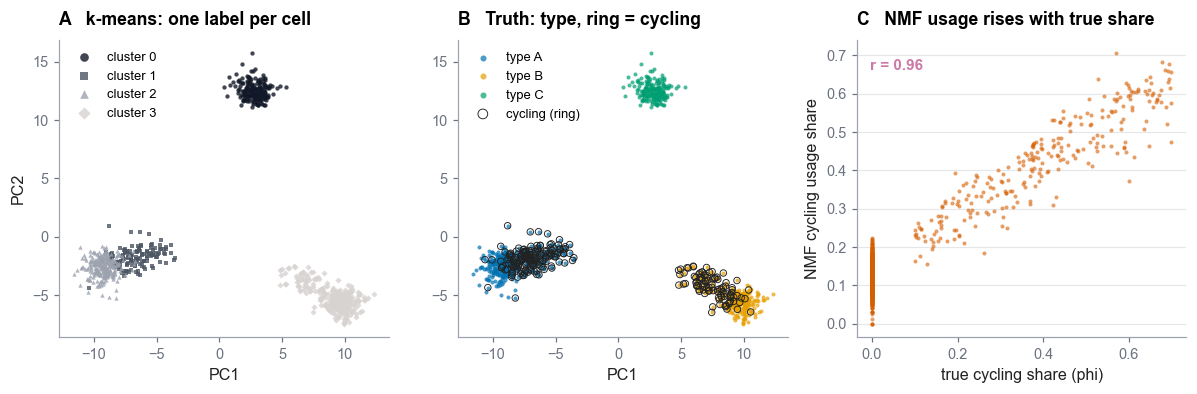

In [13]:
def draw_cluster_vs_nmf(pcs, km, m, Us):
    fig, ax = plt.subplots(1, 3, figsize=(11, 3.7))
    kcol = ["#111827", "#4B5563", "#9CA3AF", "#D6D3D1"]               # 군집 색: 프로그램 색과 겹치지 않게 회색 단계 + 모양
    kmk = ["o", "s", "^", "D"]
    for c in range(4):
        sel = km == c; ax[0].scatter(pcs[sel, 0], pcs[sel, 1], s=8, color=kcol[c], marker=kmk[c], alpha=0.8, lw=0, label=f"cluster {c}")
    ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].legend(loc="best", markerscale=2, fontsize=8.5)
    panel(ax[0], "A", "k-means: one label per cell")
    for t in "ABC":
        sel = m.type.values == t
        ax[1].scatter(pcs[sel, 0], pcs[sel, 1], s=7, color=TYPE_C[t], alpha=0.7, lw=0, label=f"type {t}")
    cyc = m.phi.values > 0
    ax[1].scatter(pcs[cyc, 0], pcs[cyc, 1], s=18, facecolors="none", edgecolors=COL["ink"], lw=0.6, label="cycling (ring)")
    ax[1].set_xlabel("PC1"); ax[1].legend(loc="best", markerscale=1.5, fontsize=8.5)
    panel(ax[1], "B", "Truth: type, ring = cycling")
    ax[2].scatter(m.phi.values, Us[:, 3], s=7, color=ACT_C, alpha=0.6, lw=0)
    ax[2].set_xlabel("true cycling share (phi)"); ax[2].set_ylabel("NMF cycling usage share")
    panel(ax[2], "C", "NMF usage rises with true share"); ygrid(ax[2])
    callout(ax[2], 0.04, 0.9, f"r = {np.corrcoef(m.phi.values, Us[:, 3])[0, 1]:.2f}", transform=ax[2].transAxes)
    plt.tight_layout(); plt.show()

draw_cluster_vs_nmf(pcs, km, m, Us)

**그림·표에서 볼 것**
- 표: 이 실행에서 군집 1 은 A 형 분열 세포 139개만 모인 군집입니다. 그러니 "A 형이면서 분열 중"이라는 무리 자체는 군집으로도 잡힙니다. 하지만
  - 분열이 약한 A 형 분열 세포 28개는 A 형 휴지 세포 225개와 같은 군집 2 에 들어갔습니다.
  - B 형은 분열 세포 95개와 휴지 세포 203개가 한 군집 3 에 섞여, B 형의 분열은 아예 보이지 않습니다.
  - 군집 1 이 B 형의 분열과 **같은 프로그램**을 쓴다는 것, 세포마다 **얼마나** 분열하는지(φ)는 군집 번호에 없습니다.

  NMF 는 하나의 분열 프로그램을 A·B 형 모두에서 찾고, 세포마다 그 몫을 줍니다(5절 E, 아래 C)(이 노트북의 시뮬레이션 결과).
- A·B: PCA 평면에서도 분열 세포(B 의 검은 고리)는 자기 세포형 무리 안에서 한쪽으로 치우쳐 있습니다. 군집 경계가 이 치우침을 자를 수 있습니다(A 의 두 군집).
- C: NMF 의 분열 usage 몫은 정답 몫(phi)이 클수록 거의 직선으로 커집니다(r 은 그림 안 숫자). 다만 usage 는 **분산을 맞춘 척도**에서의 몫이라 개수 기준인 phi 와 눈금이 같지 않고, phi = 0 인 세포도 바탕 발현 때문에 0 보다 조금 위에 모입니다. cNMF 는 마지막에 프로그램을 원래 단위인 TPM(transcripts per million, 전사체 100만 개 가운데 몇 개인가로 맞춘 발현 단위)으로 다시 맞춥니다 [1].

> **시퀀싱 데이터에서는** 종양 세포의 세포 주기, 저산소, 인터페론 반응 같은 활동은 여러 세포형·여러 클론에 걸쳐 나타납니다. 군집 대신 usage 로 보면 "이 클론은 어떤 세포형이고 얼마나 분열하나"를 함께 볼 수 있습니다.

## 7. consensus NMF: 여러 번 돌려 안정한 성분만 남기기

**한 줄 정의**: NMF 는 시작점에 따라 답이 조금씩 달라집니다. cNMF 는 (1) NMF 를 여러 번 돌리고, (2) 튀는 성분(이웃과 멀리 떨어진 것)을 걸러내고, (3) 모든 반복의 성분을 모아 군집한 뒤 **군집 중앙값**을 합의(consensus) 추정값으로 씁니다. 그다음 이 프로그램을 고정하고 usage 를 다시 구합니다 [1].

**왜 필요한가**: Kotliar 등은 ICA, LDA, NMF 를 같은 시뮬레이션 데이터에 200번씩 돌려 보니 같은 프로그램에 붙는 성분이 크게 흔들렸고, 특히 NMF 와 LDA 가 그랬다고 적었습니다 [1].

**mutational signature 와 다른 점**: cNMF 는 count 가 아닌 정규화한 행렬에 NMF 를 돌리기 때문에, 개수를 재표집하지 않고 시드(random seed)만 바꿔 반복합니다 [1]. N4 의 SigProfilerExtractor 는 반복마다 포아송 재표집을 합니다.

**실제 cNMF 와 같은 점·다른 점**
- 같은 점: 성분을 L2 길이 1 로 맞춰 모으고, 이웃 L 개와의 평균 유클리드 거리로 튀는 성분을 거르고, k-means 로 k 무리를 만들고, 무리마다 유전자별 중앙값을 씁니다. 안정성은 L2 로 맞춘 성분의 유클리드 silhouette 입니다 [1].
- 다른 점(이웃 수): cNMF 논문은 이웃 수를 반복 횟수의 30% 로 두었을 때 모든 데이터에서 잘 맞았다고 적었습니다 [1]. 이 노트북은 반복 횟수의 25%(20번 반복이면 5개)를 씁니다.
- 다른 점(거르는 기준): cNMF 는 거리 문턱 τ 를 데이터마다 "거리 분포의 긴 꼬리"를 보고 사람이 정했습니다 [1]. 이 노트북은 늘 거리 상위 10%(90% 분위수 위)를 기계적으로 버립니다. 그래서 튀는 성분이 없어도 10% 는 버려집니다(아래 표의 `filtered`).
- 다른 점(오차): cNMF 논문은 k 표의 오차를 거르기 **전** 합의 해로 계산했다고 적었습니다 [1]. 이 노트북은 거른 뒤 합의 프로그램으로 계산합니다.

In [14]:
def consensus(X, k, reps=20, n_nei=None, density_q=0.9, seed=0):
    """반복 → 성분(L2 정규화) 모으기 → 이웃 거리로 튀는 성분 거르기 → k-means 로 k 무리 → 무리 중앙값.
    반환: 합의 프로그램(k × genes), 군집 silhouette(유클리드), 걸러낸 성분 수"""
    rng = np.random.default_rng(seed); comps = []
    for r in range(reps):
        _, G, _ = fit_nmf(X, k, seed=int(rng.integers(1e9)), max_iter=600, init="random")
        comps.append(G / np.linalg.norm(G, axis=1, keepdims=True))
    A = np.vstack(comps)
    n_nei = n_nei or max(2, reps // 4)
    d, _ = NearestNeighbors(n_neighbors=n_nei + 1).fit(A).kneighbors(A)
    local = d[:, 1:].mean(1); keep = local <= np.quantile(local, density_q)
    labels = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(A[keep])
    sil = silhouette_score(A[keep], labels, metric="euclidean") if k > 1 else np.nan
    G_cons = np.vstack([np.median(A[keep][labels == j], axis=0) for j in range(k)])
    return G_cons, sil, int((~keep).sum())

def usage_given(X, G):
    """프로그램 G 를 고정하고 세포마다 NNLS 로 usage"""
    return np.vstack([nnls(G.T, x)[0] for x in X])

t0 = time.perf_counter()
rows = {}
for k in range(2, 8):
    Gc, sil, n_out = consensus(X.values, k, reps=20, seed=k)
    Uc = usage_given(X.values, Gc)
    rows[k] = dict(silhouette=round(sil, 3), rel_error=round(np.linalg.norm(X.values - Uc @ Gc) / np.linalg.norm(X.values), 4), filtered=n_out)
    if k == 4:
        G4, U4 = Gc, Uc
    if k == 5:
        G5 = Gc
ktab = pd.DataFrame(rows).T
print(f"계산 시간 {time.perf_counter() - t0:.1f}초"); print(ktab)
assert ktab.silhouette[4] == 1.0 and ktab.silhouette[5] == 0.978 and ktab.silhouette[6] == 0.863   # 아래 글이 인용하는 숫자

계산 시간 18.7초
   silhouette  rel_error  filtered
2       1.000     0.4738       4.0
3       1.000     0.3732       6.0
4       1.000     0.3354       8.0
5       0.978     0.3075      10.0
6       0.863     0.3067      12.0
7       0.806     0.3039      14.0


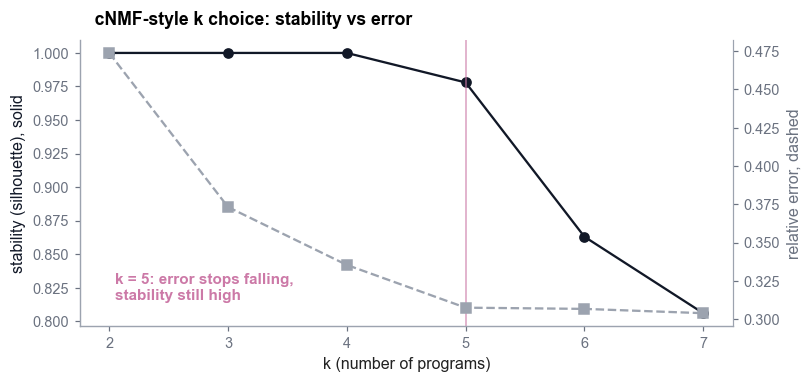

k = 5: 정답 4개와 짝지은 상관 {'A': 0.955, 'B': 0.946, 'C': 0.96, 'CYC': 0.965}
       남는 성분의 대표 유전자: ['RP11', 'RP01', 'RP06', 'RP09', 'RP08', 'RP03']


In [15]:
def draw_consensus_k(ktab, k_pick=4):
    fig, ax1 = plt.subplots(figsize=(7.5, 3.6)); ax2 = ax1.twinx()
    ax1.plot(ktab.index, ktab.silhouette, "-o", color=COL["metric"]); ax1.set_ylabel("stability (silhouette), solid", color=COL["metric"])
    ax2.plot(ktab.index, ktab.rel_error, "--s", color=COL["metric2"]); ax2.set_ylabel("relative error, dashed", color=COL["muted"])
    ax2.spines["right"].set_visible(True)
    ax1.axvline(k_pick, color=COL["highlight"], lw=1.2, alpha=0.6); ax1.set_xlabel("k (number of programs)")
    panel(ax1, "", "cNMF-style k choice: stability vs error")
    callout(ax1, ktab.index.min() + 0.05, ktab.silhouette.min() + 0.01, f"k = {k_pick}: error stops falling,\nstability still high")
    plt.tight_layout(); plt.show()

draw_consensus_k(ktab, k_pick=5)
o5, r5 = match(truth_scaled, G5.T)                                   # 정답 4개와 짝 맞추기, 남는 성분 하나
extra = [j for j in range(5) if j not in o5][0]
top_extra = pd.Series(G5[extra], index=hv).sort_values(ascending=False).index[:6]
print("k = 5: 정답 4개와 짝지은 상관", dict(zip(truth.columns, r5.round(3))))
print("       남는 성분의 대표 유전자:", list(top_extra))
assert all(g.startswith("RP") for g in top_extra[:5])

**그림에서 볼 것**: 검은 실선은 반복 결과 성분들이 무리 지어 또렷하게 갈리는 정도(silhouette), 회색 점선은 합의 프로그램으로 다시 맞춘 오차입니다. 오차는 k = 5 까지 줄고 그 뒤로는 거의 줄지 않습니다. 안정성은 k = 4 까지 1.000 이다가 k = 5 에서 조금(0.978), k = 6 부터 크게(0.863) 떨어집니다. Kotliar 등도 안정성과 오차 사이의 균형을 보고 K 를 고르라고 합니다 [1].

그런데 생물학 프로그램은 4개(A, B, C, 분열)인데 왜 5일까요? 아래 출력처럼 다섯째 성분의 대표 유전자는 RP 유전자입니다. 이 장난감에 넣은 **기술적 변동**도 성분 하나로 따로 잡힌 것입니다. 그래서 k 를 고른 뒤에는 늘 성분마다 대표 유전자를 읽고 "생물학 프로그램인가, 기술적 성분인가"를 따로 판단합니다. 4~6절은 생물학 프로그램 4개만 보려고 k = 4 로 설명했습니다.

In [16]:
o4, r4 = match(truth_scaled, G4.T)
print("k = 4 합의 프로그램과 정답의 상관:", dict(zip(truth.columns, r4.round(3))))
singles = []
for s in range(10):
    _, Gs1, _ = fit_nmf(X.values, 4, seed=100 + s, max_iter=600, init="random")
    singles.append(match(truth_scaled, Gs1.T)[1].min())
print("한 번씩 돌린 10회의 '가장 낮은 상관' 범위:", round(min(singles), 3), "~", round(max(singles), 3))
assert r4.min() > 0.9

k = 4 합의 프로그램과 정답의 상관: {'A': 0.964, 'B': 0.968, 'C': 0.971, 'CYC': 0.977}


한 번씩 돌린 10회의 '가장 낮은 상관' 범위: 0.964 ~ 0.965


**표에서 볼 것**: 합의 프로그램은 네 개 모두 정답과 상관이 높습니다. 이 장난감에서는 한 번씩 돌린 결과도 거의 같습니다(가장 낮은 상관의 범위가 아주 좁음). 프로그램이 뚜렷하게 갈리는 쉬운 데이터이기 때문입니다. Kotliar 등은 시뮬레이션 데이터에 NMF 를 200번 돌렸을 때 같은 프로그램에 붙는 성분이 크게 흔들렸다고 보고했고, 그래서 consensus 를 씁니다 [1].

## 8. 다른 응용 세 가지

### 8-1. CN signature: 구간을 48칸으로 세기

**한 줄 정의**: 표본의 copy number 구간을 (이형접합 상태 × 총 copy 수 × 구간 크기) 48칸으로 세어 표본 × 48 행렬을 만들고, NMF 로 signature 를 뽑습니다 [3].

**숫자로 따라가기**(Steele 등의 분류 [3]): 이형접합 상태 3가지(이형접합 A>0·B>0, LOH A>0·B=0, 동형접합 결실 A=B=0), 총 copy 수(TCN) 0, 1, 2, 3–4, 5–8, 9+, 구간 크기 0–100 kb, 100 kb–1 Mb, 1–10 Mb, 10–40 Mb, >40 Mb(동형접합 결실은 가장 큰 칸이 >1 Mb).

| 상태 | 가능한 TCN | TCN 칸 | 크기 칸 | 칸 수 |
|---|---|---|---|---|
| 이형접합 | 2, 3–4, 5–8, 9+ | 4 | 5 | 20 |
| LOH | 1, 2, 3–4, 5–8, 9+ | 5 | 5 | 25 |
| 동형접합 결실 | 0 | 1 | 3 | 3 |
| 합 | | | | **48** |

칸 수 계산은 위 분류에서 이 노트북이 센 것입니다. Steele 등은 TCGA 9,873 개 종양에서 SigProfilerExtractor 로 CN signature 를 뽑았습니다. k 마다 포아송 재표집한 행렬에 무작위 시작점으로 NMF 를 **250번** 돌렸습니다 [3]. 생물학적 signature 21 개(CN1–CN21)와 함께, copy number 구간이 지나치게 잘게 쪼개진 탓(oversegmentation)으로 보이는 **인공 signature 3 개(CN22–CN24)**도 나왔습니다. 이 셋은 이후 분석에서 뺐고, 이 셋이 조금이라도 배정된 표본(116 개)도 뺐습니다 [3]. 7절의 RP 성분처럼, NMF 성분 가운데에는 데이터 처리의 흔적이 섞일 수 있습니다.

In [17]:
het, loh, hd = 4 * 5, 5 * 5, 1 * 3
assert het + loh + hd == 48

### 8-2. metagene: 유전자 수천 개를 몇 개의 묶음으로

Brunet 등은 NMF 로 발현 데이터를 유전자 수천 개에서 몇 개의 metagene 으로 줄이고, 무작위 시작점에 따라 흔들리는 알고리즘에 맞춘 모형 선택(몇 개로 나눌지 고르는 방법)과 함께 써서 암 마이크로어레이 데이터에서 의미 있는 분자 패턴을 찾았다고 보고했습니다. 계층적 클러스터링 등보다 유전자 선택과 초기값에 덜 민감했다고 적었습니다 [4]. 이 모형 선택은 N3 의 consensus·cophenetic 방법입니다.

### 8-3. 토픽 모형과 닮은 점(비유)

Lee 와 Seung 은 NMF 가 얼굴의 부분과 글의 의미 특징(semantic features of text)을 배운다고 보였습니다 [5]. Kotliar 등은 NMF 와 함께 LDA(토픽 모형)도 단일세포 데이터를 나누는 방법으로 다뤘습니다 [1]. 이 노트북의 비유로 정리하면 아래와 같습니다.

| | 글(토픽 모형) | mutational signature | 발현 프로그램 |
|---|---|---|---|
| 표본 | 문서 | 종양 | 세포 |
| 특징 | 단어 | 96칸 | 유전자 |
| 성분 | 토픽 | signature | 프로그램 |
| 양 | 문서의 토픽 비율 | 노출량 | usage |

## 연습 문제

1. 세포 2,000개 × 유전자 3,000개 행렬에서 프로그램 12개를 찾으면 U 와 G 의 모양은? scikit-learn 에 넣을 때 전치가 필요한가요?
2. 4절 끝에서 분산을 맞추지 않은 NMF 를 k = 5 로 돌리면 분열 프로그램을 되찾을까요? 왜 그럴까요?
3. `simulate_cells` 에서 C 형에도 분열을 켜면(`act_frac=(0.4, 0.3, 0.3)`) 5절 E 그림은 어떻게 바뀔까요?
4. CN 48칸에서 크기 칸을 4개로 줄이면(동형접합 결실은 그대로 3) 칸은 몇 개가 되나요?

<details><summary>정답 보기</summary>

1. U 는 2,000 × 12, G 는 12 × 3,000. 세포 × 유전자는 scikit-learn 의 표본 × 특징과 같으니 전치하지 않습니다.
2. 아래 셀에서 직접 계산합니다. 성분을 하나 더 주면 RP 흔들림이 성분 하나를 쓰고 남은 성분으로 분열 프로그램을 찾을 수 있습니다. 대신 기술적 변동에 성분을 쓰게 됩니다(이 노트북의 시뮬레이션 결과, 아래 숫자 참고).
3. C 형 세포 묶음에도 빨간 분열 몫이 생깁니다. 활동 프로그램은 세포형과 상관없이 켜질 수 있기 때문입니다.
4. 이형접합 4 × 4 = 16, LOH 5 × 4 = 20, 동형접합 결실 3 → 39 칸.

</details>

In [18]:
_, Graw5, _ = fit_nmf(C[hv].values, 5)
C5 = corr_cols(truth_scaled, (Graw5 / sd_hv).T)                   # 정답 4 × 성분 5
print("k = 5, 맞추지 않음: 정답 프로그램마다 가장 닮은 성분의 상관", dict(zip(truth.columns, C5.max(1).round(3))))
assert 4 * 4 + 5 * 4 + 3 == 39

k = 5, 맞추지 않음: 정답 프로그램마다 가장 닮은 성분의 상관 {'A': 0.94, 'B': 0.953, 'C': 0.966, 'CYC': 0.993}


## 정리

- 세포형 프로그램은 한 세포형에서, 활동 프로그램은 여러 세포형에서 켜집니다. NMF 는 세포마다 여러 프로그램의 몫(usage)을 주므로 둘을 함께 잡습니다 [1].
- 세포 × 유전자는 scikit-learn 의 표본 × 특징과 방향이 같습니다. U = `fit_transform`, G = `components_` 입니다 [2].
- cNMF 는 흔들리는 유전자를 고르고, 유전자마다 표준편차로 나눠(평균은 빼지 않고) NMF 에 넣습니다. 큰 유전자가 오차를 독차지하지 않게 하기 위해서입니다 [1].
- 한 번의 NMF 는 흔들리므로 여러 번 돌려 튀는 성분을 거르고 군집 중앙값을 씁니다. 정규화한 행렬이라 재표집 대신 시드만 바꿉니다 [1].
- 같은 틀을 CN 구간(48칸, [3]), 발현 metagene([4]), 글의 토픽(비유)에도 씁니다.

## 출처

| 번호 | 출처 | 이 노트북의 어느 주장에 썼나 |
|---|---|---|
| [1] | Kotliar D, Veres A, Nagy MA, et al. (2019). Identifying gene expression programs of cell-type identity and cellular activity with single-cell RNA-Seq. *eLife* 8:e43803. [doi:10.7554/eLife.43803](https://doi.org/10.7554/eLife.43803), [PMC6639075](https://pmc.ncbi.nlm.nih.gov/articles/PMC6639075/) | 세포형·활동 프로그램, "Unlike hard clustering … matrix factorization allows cells to express multiple GEPs", 시뮬레이션 식 λ = L(φZa + (1−φ)Z_I)와 φ ~ U(0.1, 0.7), UMI 1000 미만 세포·500 세포 중 1 미만 유전자 제거, v-score 상위 2000 유전자, 단위 분산 맞추기와 그 이유, usage 를 세포마다 합 1, 반복·이상 성분 거르기(이웃 수 = 반복의 30%, 문턱 τ 는 거리 분포의 긴 꼬리로)·k-means·군집 중앙값·유클리드 silhouette·오차는 거르기 전 합의 해로, "It is essential to select a subset of over-dispersed genes prior to normalization …", Splatter 기반 시뮬레이션과 λ 가 잡음 전 평균(pre-trended mean), TPM 으로 되돌리기, 정규화 행렬이라 재표집 없이 시드만 바꿈, 200번 반복 시 NMF·LDA 의 흔들림, 안정성·오차로 K 선택, LDA 를 함께 다룸 |
| [2] | scikit-learn 1.4 문서, `sklearn.decomposition.NMF`. [링크](https://scikit-learn.org/1.4/modules/generated/sklearn.decomposition.NMF.html) | X `(n_samples, n_features)`, W `(n_samples, n_components)`, `components_` `(n_components, n_features)` |
| [3] | Steele CD, Abbasi A, Islam SMA, et al. (2022). Signatures of copy number alterations in human cancer. *Nature* 606:984–991. [doi:10.1038/s41586-022-04738-6](https://doi.org/10.1038/s41586-022-04738-6), [PMC9242861](https://pmc.ncbi.nlm.nih.gov/articles/PMC9242861/) | 48칸 분류(이형접합 상태·TCN·구간 크기와 각 구간 경계), TCGA 9,873 종양, SigProfilerExtractor 의 NMF 와 포아송 재표집, k 마다 250번 반복·무작위 시작점, 21 개 CN signature, oversegmentation 으로 보이는 인공 signature 3 개(CN22–CN24)와 그 116 표본 제외 |
| [4] | Brunet JP, Tamayo P, Golub TR, Mesirov JP (2004). Metagenes and molecular pattern discovery using matrix factorization. *PNAS* 101(12):4164–4169. [doi:10.1073/pnas.0308531101](https://doi.org/10.1073/pnas.0308531101) | metagene, 무작위 알고리즘용 모형 선택, 계층적 클러스터링보다 유전자 선택·초기값에 덜 민감(초록에서 확인, 본문 미확인) |
| [5] | Lee DD, Seung HS (1999). Learning the parts of objects by non-negative matrix factorization. *Nature* 401:788–791. [doi:10.1038/44565](https://doi.org/10.1038/44565) | "learn parts of faces and semantic features of text"(초록) |
| [6] | Klein AM, Mazutis L, Akartuna I, et al. (2015). Droplet barcoding for single-cell transcriptomics applied to embryonic stem cells. *Cell* 161(5):1187–1201. [doi:10.1016/j.cell.2015.04.044](https://doi.org/10.1016/j.cell.2015.04.044), [PMC4441768](https://pmc.ncbi.nlm.nih.gov/articles/PMC4441768/) | cNMF 가 v-score 의 출처로 인용; 본문의 above-Poisson noise 정의 "CV² − 1/μ"(v-score 의 정확한 식은 보충 자료, 미확인) |

이 노트북에서 직접 계산한 것(장난감 데이터, 분산 몫, 상관, 군집 교차표, k 표)은 **이 노트북의 시뮬레이션 결과**입니다.